# Course 11: On-Device AI
## Session 9: Small language models and speech on the phone

**Goal:** estimate decoding speed from memory bandwidth, measure what a KV cache and int8 quantization change in a small language model, and choose a model and runtime for a phone.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Decoding is limited by memory bandwidth
To generate one token, a language model multiplies the new token's vector by every weight matrix: a matrix–**vector** product, about 2 floating-point operations (FLOPs) for every weight read. A phone or laptop computes far faster than it can read memory, so the time per token is about **model bytes ÷ memory bandwidth**. Processing a prompt (**prefill**) multiplies the same matrices by many token vectors at once, a matrix–**matrix** product, so each weight read is reused for many tokens.

We measure this on one core of this server with one 12,288 × 8,192 float32 matrix (403 MB, larger than this CPU's caches, so it must stream from main memory), multiplying it by 1 to 256 token vectors. All timings are single-thread medians on a shared server CPU, not a phone.

weight matrix: 402.7 MB
 tokens  ms_total  ms_per_token  weight_GB_per_s  GFLOP_per_s
      1     27.49         27.49            14.65         7.32
      8    100.44         12.55             4.01        16.04
     32     92.79          2.90             4.34        69.43
    128    220.78          1.72             1.82       116.72

one token (decode): the weights streamed at 14.6 GB/s; 7.3 GFLOP/s
128 tokens together (prefill): 116.7 GFLOP/s, 15.9 times cheaper per token


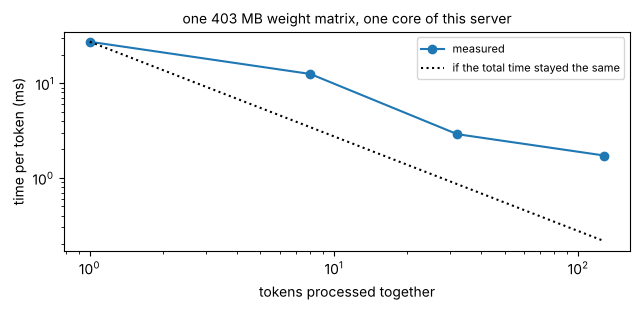

In [1]:
import io, math, os, random, time, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

t_start = time.time()
torch.set_num_threads(1); torch.manual_seed(0); np.random.seed(0)

def median_time(f, reps):
    f()                                                    # one warm-up call
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

W = torch.randn(12288, 8192)                               # one large weight matrix, float32
w_bytes = W.numel() * 4
rows = []
for n in [1, 8, 32, 128]:
    X = torch.randn(n, 8192)
    t = median_time(lambda: X @ W.T, reps=7 if n < 128 else 3)
    rows.append(dict(tokens=n, ms_total=1e3 * t, ms_per_token=1e3 * t / n, weight_GB_per_s=w_bytes / t / 1e9, GFLOP_per_s=2 * n * W.numel() / t / 1e9))
bw = pd.DataFrame(rows)
print(f"weight matrix: {w_bytes / 1e6:.1f} MB")
print(bw.round(2).to_string(index=False))
decode_bw = bw.weight_GB_per_s[0]
print(f"\none token (decode): the weights streamed at {decode_bw:.1f} GB/s; {bw.GFLOP_per_s[0]:.1f} GFLOP/s")
print(f"128 tokens together (prefill): {bw.GFLOP_per_s.iloc[-1]:.1f} GFLOP/s, {bw.ms_per_token[0] / bw.ms_per_token.iloc[-1]:.1f} times cheaper per token")
del W, X

plt.figure(figsize=(6.5, 3.2))
plt.loglog(bw.tokens, bw.ms_per_token, "o-", label="measured")
plt.loglog(bw.tokens, bw.ms_per_token[0] / bw.tokens, "k:", label="if the total time stayed the same")
plt.xlabel("tokens processed together"); plt.ylabel("time per token (ms)")
plt.title("one 403 MB weight matrix, one core of this server", fontsize=10); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 2. A tokens-per-second table
If decoding reads every weight once per token, an upper bound is **tokens per second ≈ bandwidth ÷ bytes per token**. Bytes per token are the parameters times the bits per weight divided by 8; group-wise int8 and int4 add a 16-bit scale for every 32 weights, so they cost 8.5 and 4.5 bits per weight (session 4). The model sizes are example sizes of small open models.

The phone bandwidths are **assumptions**, the theoretical peaks of common memory types: LPDDR4X at 4,266 million transfers per second on a 32-bit or 64-bit bus (17.1 and 34.1 GB/s), and LPDDR5X at 8,533 on a 64-bit bus (68.3 GB/s). Real phones reach less than the peak, the CPU cores alone may not reach it at all, and the phone's other work shares it. The last column uses the bandwidth measured in section 1 on one core of this server.

In [2]:
bandwidths = {"17.1 GB/s*": 17.1e9, "34.1 GB/s*": 34.1e9, "68.3 GB/s*": 68.3e9, f"{decode_bw:.1f} GB/s (server)": decode_bw * 1e9}
formats = {"float16": 16, "int8 + scales": 8.5, "int4 + scales": 4.5}
rows = []
for params in [0.5e9, 1e9, 3e9, 7e9]:
    for fmt, bits in formats.items():
        size = params * bits / 8
        row = {"parameters": f"{params / 1e9:g} B", "format": fmt, "weights (GB)": round(size / 1e9, 2)}
        row.update({bw_name: round(b / size, 1) for bw_name, b in bandwidths.items()})
        rows.append(row)
table = pd.DataFrame(rows)
with pd.option_context("display.width", 200):
    print("upper bound on tokens per second = bandwidth / weight bytes   (* assumed phone bandwidths; server = measured in section 1)")
    print(table.to_string(index=False))
kv = 2 * 16 * 8 * 64 * 4096 * 2                            # session 8, example A, float16, 4,096 tokens
w1b = 1e9 * 4.5 / 8
print(f"\nreading a 4,096-token KV cache too (session 8, example A: {kv / 1e6:.0f} MB) adds {100 * kv / w1b:.0f}% to the bytes "
      f"per token of a 1 B int4 model, so the bound drops from {34.1e9 / w1b:.1f} to {34.1e9 / (w1b + kv):.1f} tokens/s at 34.1 GB/s")

upper bound on tokens per second = bandwidth / weight bytes   (* assumed phone bandwidths; server = measured in section 1)
parameters        format  weights (GB)  17.1 GB/s*  34.1 GB/s*  68.3 GB/s*  14.6 GB/s (server)
     0.5 B       float16          1.00        17.1        34.1        68.3                14.6
     0.5 B int8 + scales          0.53        32.2        64.2       128.6                27.6
     0.5 B int4 + scales          0.28        60.8       121.2       242.8                52.1
       1 B       float16          2.00         8.6        17.1        34.1                 7.3
       1 B int8 + scales          1.06        16.1        32.1        64.3                13.8
       1 B int4 + scales          0.56        30.4        60.6       121.4                26.0
       3 B       float16          6.00         2.9         5.7        11.4                 2.4
       3 B int8 + scales          3.19         5.4        10.7        21.4                 4.6
       3 B int4 + scal

### 3. A tiny character-level language model
We now build a real (tiny) language model to measure. The text is **synthetic**: 3,000 sentences generated from a small grammar ("the farmer in sylhet sold 12 kg of rice on monday."), 2,700 for training and 300 for validation. Real small language models are trained on trillions of tokens of web text, and for Bangla you would use the data and tokenizer from Course 5. The model is a 2-layer Transformer with 64-dimensional embeddings, written so that it can keep a **KV cache**: each attention layer stores the keys and values it has already computed. Training takes about half a minute.

In [3]:
rng = random.Random(0)
subjects = ["the farmer", "the teacher", "my sister", "a student", "the doctor", "our neighbour", "the shopkeeper", "the fisherman", "my uncle", "the nurse"]
places = ["in rangpur", "in khulna", "in sylhet", "near the river", "at the market", "in the village", "in dhaka", "in barishal", "in rajshahi", "on the boat"]
actions = [("sold", "kg of rice"), ("bought", "mangoes"), ("caught", "fish"), ("read", "pages"), ("walked", "km"), ("sent", "messages"),
           ("planted", "trees"), ("charged the phone for", "minutes"), ("paid", "taka for tea"), ("carried", "bags of potatoes")]
times_ = ["on monday", "on tuesday", "on wednesday", "on thursday", "on friday", "this morning", "last night", "after the rain", "before the exam", "during the flood"]
def sentence():
    verb, obj = rng.choice(actions)
    return f"{rng.choice(subjects)} {rng.choice(places)} {verb} {rng.randint(2, 40)} {obj} {rng.choice(times_)}."
sents = [sentence() for _ in range(3000)]
text_train, text_val = "\n".join(sents[:2700]) + "\n", "\n".join(sents[2700:]) + "\n"
chars = sorted(set(text_train + text_val)); stoi = {c: i for i, c in enumerate(chars)}
encode = lambda s: torch.tensor([stoi[c] for c in s])
decode = lambda ids: "".join(chars[i] for i in ids)
train_ids, val_ids = encode(text_train), encode(text_val)
print(f"vocabulary {len(chars)} characters; {len(train_ids):,} training and {len(val_ids):,} validation characters")
print("example sentences:", sents[0], "|", sents[1])

class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.heads = heads
        self.ln1, self.qkv, self.proj = nn.LayerNorm(d), nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ln2, self.fc1, self.fc2 = nn.LayerNorm(d), nn.Linear(d, 4 * d), nn.Linear(4 * d, d)
    def forward(self, x, cache=None):
        B, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, T, 3, self.heads, D // self.heads).permute(2, 0, 3, 1, 4)
        if cache is not None:                               # KV cache: append this step's keys and values to the stored ones
            if "k" in cache:
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, is_causal=T > 1)   # one new token may look at every cached token
        x = x + self.proj(y.transpose(1, 2).reshape(B, T, D))
        return x + self.fc2(F.gelu(self.fc1(self.ln2(x))))

class TinyLM(nn.Module):
    def __init__(self, vocab, d=64, heads=4, layers=2, block=256):
        super().__init__()
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(block, d)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(layers)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, vocab)
    def forward(self, idx, caches=None, start=0):
        x = self.tok(idx) + self.pos(torch.arange(start, start + idx.shape[1]))
        for i, b in enumerate(self.blocks):
            x = b(x, None if caches is None else caches[i])
        return self.head(self.ln(x))

model = TinyLM(len(chars))
n_params = sum(p.numel() for p in model.parameters())
opt = torch.optim.AdamW(model.parameters(), lr=6e-3, weight_decay=0.01)
B, T, steps = 8, 256, 700
t0 = time.time()
for step in range(steps):
    for g in opt.param_groups:                              # warm-up, then cosine decay
        g["lr"] = 6e-3 * min(1, (step + 1) / 20) * 0.5 * (1 + math.cos(math.pi * step / steps))
    ix = torch.randint(0, len(train_ids) - T - 1, (B,))
    xb = torch.stack([train_ids[i:i + T] for i in ix]); yb = torch.stack([train_ids[i + 1:i + T + 1] for i in ix])
    loss = F.cross_entropy(model(xb).flatten(0, 1), yb.flatten())
    opt.zero_grad(); loss.backward(); opt.step()
model.eval()

def val_loss(m):
    n = (len(val_ids) - 1) // T
    X, Y = val_ids[:n * T].view(n, T), val_ids[1:n * T + 1].view(n, T)
    with torch.inference_mode():
        return F.cross_entropy(m(X).flatten(0, 1), Y.flatten()).item()

loss_fp32 = val_loss(model)
print(f"{n_params:,} parameters ({4 * n_params / 1e6:.2f} MB in float32); trained {steps} steps in {time.time() - t0:.0f} s")
print(f"validation loss {loss_fp32:.4f} nats per character = {loss_fp32 / math.log(2):.3f} bits per character")

vocabulary 37 characters; 152,853 training and 17,107 validation characters
example sentences: the shopkeeper in rangpur planted 18 trees before the exam. | the shopkeeper at the market charged the phone for 32 minutes this morning.


121,253 parameters (0.49 MB in float32); trained 700 steps in 28 s
validation loss 0.3255 nats per character = 0.470 bits per character


### 4. Generation with and without a KV cache
Without a cache, every new token runs the whole model over the whole text so far, so the cost per token grows with the position. With the cache, each step runs the model on one new token and attends to the stored keys and values. We generate 230 characters greedily (always the most likely next character) both ways, time every step, and check that the two texts are identical.

generated text (with cache):
the farmer in sylhet paid 12 taka for tea on thursday.
the fisherman in rajshahi caught 22 fish on tuesday.
the shopkeeper in rajshahi caught 1 fish on thursday.
the fisherman in the village caught 2 fish on tuesday.
the shopkeeper in barishal caught

identical text with and without the cache: True
with KV cache : steps 2-21 0.30 ms/token, last 20 steps 0.27 ms/token, whole text 0.06 s
without cache : steps 2-21 0.55 ms/token, last 20 steps 2.09 ms/token, whole text 0.26 s


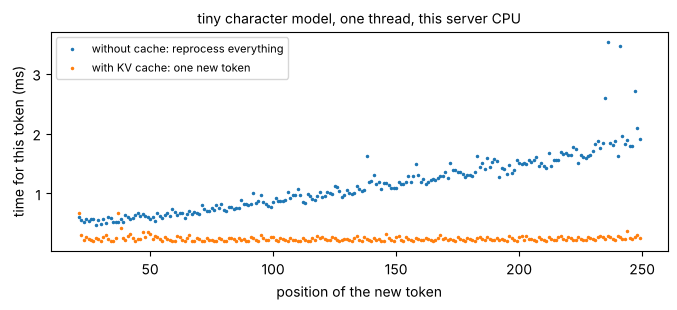

In [4]:
def generate(m, prompt, n_new, use_cache):
    idx, step_times = encode(prompt)[None], []
    with torch.inference_mode():
        caches = [dict() for _ in m.blocks] if use_cache else None
        if use_cache:
            logits = m(idx, caches, 0)                      # prefill: the whole prompt in one call
        for t in range(n_new):
            t0 = time.perf_counter()
            if not use_cache:
                logits = m(idx)                             # recompute everything from the start
            elif t > 0:
                logits = m(idx[:, -1:], caches, idx.shape[1] - 1)   # only the newest token
            nxt = logits[0, -1].argmax().view(1, 1)
            idx = torch.cat([idx, nxt], 1)
            step_times.append(time.perf_counter() - t0)
    return decode(idx[0].tolist()), np.array(step_times)

prompt = "the farmer in sylhet"
text_c, t_cache = generate(model, prompt, 230, use_cache=True)
text_n, t_nocache = generate(model, prompt, 230, use_cache=False)
print("generated text (with cache):")
print(text_c)
print(f"\nidentical text with and without the cache: {text_c == text_n}")
pos = np.arange(len(prompt), len(prompt) + 230)
for name, ts in [("with KV cache", t_cache), ("without cache", t_nocache)]:
    print(f"{name:14s}: steps 2-21 {1e3 * ts[1:21].mean():.2f} ms/token, last 20 steps {1e3 * ts[-20:].mean():.2f} ms/token, "
          f"whole text {ts.sum():.2f} s")

plt.figure(figsize=(7, 3.2))
plt.plot(pos[1:], 1e3 * t_nocache[1:], ".", ms=3, label="without cache: reprocess everything")
plt.plot(pos[1:], 1e3 * t_cache[1:], ".", ms=3, label="with KV cache: one new token")
plt.xlabel("position of the new token"); plt.ylabel("time for this token (ms)")
plt.title("tiny character model, one thread, this server CPU", fontsize=10); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 5. Dynamic int8 quantization of the linear layers
`torch.ao.quantization.quantize_dynamic` stores each `nn.Linear` weight in int8 and quantizes the activations at run time (as ONNX Runtime did in session 7). It still works in this PyTorch version but is deprecated: PyTorch is moving quantization to the separate `torchao` package (Course 5 session 10 uses the same function), so we hide its warnings. We compare the saved size, the validation loss, the time per generated token with the cache, and the generated text. Finally we compare the measured speed with the bandwidth bound of section 2.

In [5]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                         # deprecation warnings about the move to torchao
    qmodel = torch.ao.quantization.quantize_dynamic(model, {nn.Linear}, dtype=torch.qint8)

def saved_bytes(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.tell()

loss_int8 = val_loss(qmodel)
text_q, t_q = generate(qmodel, prompt, 230, use_cache=True)
_, t_c2 = generate(model, prompt, 230, use_cache=True)      # time float32 again, right next to int8
same = next((i for i, (a, b) in enumerate(zip(text_q, text_c)) if a != b), None)
print(f"saved size: float32 {saved_bytes(model):,} bytes, int8 linear layers {saved_bytes(qmodel):,} bytes")
print(f"validation loss: float32 {loss_fp32:.4f}, int8 {loss_int8:.4f} ({100 * (loss_int8 / loss_fp32 - 1):+.2f}%)")
print(f"median time per token with the cache: float32 {1e3 * np.median(t_c2[1:]):.3f} ms, int8 {1e3 * np.median(t_q[1:]):.3f} ms")
print("int8 text is identical to float32" if same is None else f"int8 text first differs from float32 at character {same}")
print(text_q[:120])
tok_s = 1 / np.median(t_c2[1:])
print(f"\nmeasured: {tok_s:,.0f} tokens/s in float32; the bandwidth bound for {4 * n_params / 1e6:.2f} MB of weights at "
      f"{decode_bw:.1f} GB/s would be {decode_bw * 1e9 / (4 * n_params):,.0f} tokens/s")
print(f"runtime so far {time.time() - t_start:.0f} s")

saved size: float32 494,281 bytes, int8 linear layers 198,931 bytes
validation loss: float32 0.3255, int8 0.3395 (+4.29%)
median time per token with the cache: float32 0.395 ms, int8 0.543 ms
int8 text first differs from float32 at character 143
the farmer in sylhet paid 12 taka for tea on thursday.
the fisherman in rajshahi caught 22 fish on tuesday.
the shopkeep

measured: 2,529 tokens/s in float32; the bandwidth bound for 0.49 MB of weights at 14.6 GB/s would be 30,202 tokens/s
runtime so far 34 s


### 6. Real models on a phone or laptop (NOT RUN here)
**llama.cpp** runs language models stored in its GGUF format on CPUs (including phones' Arm CPUs) and GPUs, and memory-maps the weights (session 8). The cell below builds it and measures prompt-processing and generation speed for a small model that you download yourself as a GGUF file at about 4 bits per weight, with 1 and 4 threads. Compare the generation speed with your row of the table in section 2.

In [ ]:
# NOT RUN: needs git, cmake, a C++ compiler and a downloaded GGUF model file (run on Colab, Kaggle or a laptop)
!git clone https://github.com/ggml-org/llama.cpp
!cmake -S llama.cpp -B llama.cpp/build -DCMAKE_BUILD_TYPE=Release && cmake --build llama.cpp/build -j 4
MODEL = "path/to/a-small-model-Q4_K_M.gguf"    # a 0.5-1 B parameter model at about 4 bits per weight, from its official page
# -p: prompt tokens processed at once (prefill), -n: tokens generated one by one (decode), -t: threads to try
!llama.cpp/build/bin/llama-bench -m {MODEL} -p 128 -n 64 -t 1,4

**whisper.cpp** runs OpenAI's Whisper speech recognition models the same way. The multilingual `tiny` model has 39 million parameters (about 78 MB in float16) and `base` 74 million (Radford et al. 2022). Whisper reads audio in 30-second windows; on a phone, streaming apps run it again and again on a sliding window. Try a short Bangla clip (`-l bn`) as well as the English sample, and compare the speed and the errors (Course 12, session 2 treats Bangla speech recognition properly).

In [ ]:
# NOT RUN: needs git, cmake, a C++ compiler and a model download (whisper.cpp; run on Colab, Kaggle or a laptop)
!git clone https://github.com/ggml-org/whisper.cpp
!cmake -S whisper.cpp -B whisper.cpp/build -DCMAKE_BUILD_TYPE=Release && cmake --build whisper.cpp/build -j 4
!bash whisper.cpp/models/download-ggml-model.sh tiny
!whisper.cpp/build/bin/whisper-cli -m whisper.cpp/models/ggml-tiny.bin -f whisper.cpp/samples/jfk.wav -t 4
# your own clip: 16 kHz mono 16-bit WAV, Bangla
!whisper.cpp/build/bin/whisper-cli -m whisper.cpp/models/ggml-tiny.bin -f my_bangla_clip.wav -l bn -t 4

### 7. Exercises

In [6]:
# TODO: speculative decoding (Leviathan et al. 2023). A small draft model proposes k tokens; the large model checks them
# in one pass. If each draft token is accepted with probability a, the expected number of tokens per large-model pass is
# (1 - a**(k + 1)) / (1 - a). If one draft step costs c times a large-model step, the expected speed-up is that number
# divided by (c * k + 1). Compute the speed-up for a = 0.6, 0.8, 0.9, k = 1 to 8 and c = 0.05 and 0.2, and say which
# k is best. Then explain why a draft model also costs memory on a phone.
def speculative_speedup(a, k, c):
    return None          # replace with your code

r = speculative_speedup(0.8, 4, 0.05)
print("not done yet" if r is None else f"speed-up {r:.2f}")

not done yet


In [7]:
# TODO: your phone. Find your phone's memory type and bus width (or use an assumed bandwidth), then compute the
# tokens-per-second bound for a 1 B and a 3 B model at 4.5 bits per weight, including a 2,048-token KV cache for a
# model shaped like session 8's example A. If you can, compare with llama-bench on the phone (for example in Termux).
def phone_bound(bandwidth_gb_s, params, bits=4.5, kv_bytes=0):
    return None          # replace with your code

r = phone_bound(25.0, 1e9)
print("not done yet" if r is None else f"{r:.1f} tokens/s")

not done yet


### What to notice
(Written from the saved run. Sizes, losses and generated text will match yours; timings change from run to run on this shared server and are not phone timings.)

1. **Decoding is a memory problem; prefill is not.** Multiplying the 403 MB matrix by one token vector took 27.49 ms: the weights streamed at 14.6 GB/s, but the core did only 7.3 GFLOP/s of arithmetic. With 128 tokens at once it reached 116.7 GFLOP/s, and each token became 15.9 times cheaper. Eight tokens took 100.44 ms, almost four times the single token: the cost per token falls unevenly, because the library uses different kernels for different sizes.
2. **The table gives upper bounds, not phone measurements.** A 1-billion-parameter model at 4.5 bits per weight is 0.56 GB, so it can generate at most 30.4 tokens per second at an assumed 17.1 GB/s and 121.4 at 68.3 GB/s. A 7 B model in float16 (14 GB) would not fit in most phones' RAM, and would manage only 1.2 to 4.9 tokens per second. Reading a 4,096-token KV cache as well adds 24% to the bytes per token of the 1 B int4 model.
3. **The tiny model learned the grammar, with plausible mistakes.** Its 121,253 parameters reached a validation loss of 0.3255 nats per character (0.470 bits) in 700 steps, and it generated well-formed sentences such as "the farmer in sylhet paid 12 taka for tea on thursday." But it also wrote "caught 1 fish", although the grammar only uses numbers from 2 to 40.
4. **The KV cache kept the cost per token flat.** Both ways gave identical text. With the cache, each token took about 0.3 ms at every position; without it, the time grew from 0.55 ms to 2.09 ms per token by position 250, and the whole text took 0.26 s instead of 0.06 s. (The few scattered high points are other jobs on this shared machine.) For real models with thousands of tokens of context, the gap is far larger.
5. **Dynamic int8 made the file smaller, the loss worse, and this tiny model slower.** The saved model shrank from 494,281 to 198,931 bytes, 2.5 times rather than 4, because the embeddings, layer norms and biases stay in float32. The validation loss rose by 4.29% (0.3255 to 0.3395), and the generated text matched float32 for 143 characters and then changed. Each token took 0.543 ms against 0.395 ms in float32: for matrices this small, quantizing the activations at every step costs more than the int8 arithmetic saves. Small models can lose more from quantization than large ones (Course 5 session 10), so measure.
6. **The bandwidth rule does not describe tiny models.** Our 0.49 MB model ran at 2,529 tokens per second, far below the bandwidth bound of 30,202, because Python and per-operator overhead dominate. The rule is a good first estimate when the weights are hundreds of megabytes or more, as in a 1 B model on a phone; then check it with `llama-bench` on the device.